# RAG Failure Modes: An Empirical Study
### *When retrieval succeeds but generation still hallucinates — and vice versa*

**Prepared for:** ICAAD 2026 (International Conference on AI Across Disciplines) — Track: *Natural Language Processing & Large Language Models*

**Research question:** When a Retrieval-Augmented Generation (RAG) pipeline produces a wrong or hallucinated answer, is the failure caused by (a) **retrieval mismatch** (the relevant document was never retrieved), or (b) **generation ignoring context** (the correct document was retrieved, but the model still answered incorrectly / ungrounded)?

**Approach:**
1. Build a QA corpus with a known "gold" supporting document per question (from SQuAD), plus distractor documents to make retrieval non-trivial.
2. Run a standard dense-retrieval + LLM-generation RAG pipeline.
3. Also run a **closed-book** (no-retrieval) baseline with the same LLM, to separate "the model already knew this" from "retrieval actually helped."
4. Score answer correctness (EM/F1) and **faithfulness** (does the retrieved context actually entail the generated answer, via an NLI model?).
5. Cross-tabulate retrieval success × answer correctness × faithfulness into a failure taxonomy, visualize, and pull qualitative case studies.

> This notebook is designed to run end-to-end on a free Google Colab GPU runtime (Runtime → Change runtime type → T4 GPU). CPU also works, just slower for generation.


## 0. Setup

In [ ]:
!pip install -q sentence-transformers faiss-cpu transformers datasets accelerate evaluate sacrebleu


In [ ]:
import random
import re
import string
import collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
import faiss
from transformers import pipeline, AutoTokenizer, AutoModelForSeq2SeqLM

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)


Using device: cuda


## 1. Build the QA set + retrieval corpus

We use a subset of **SQuAD v1.1** (validation split). Each SQuAD question is paired with exactly one gold context paragraph, which makes it easy to check whether retrieval "found the right document."

To make retrieval non-trivial (i.e., not just returning whatever's in a 5-document corpus), we add a large pool of **distractor paragraphs** drawn from other, unrelated SQuAD contexts.

Adjust `N_QUESTIONS` and `N_DISTRACTORS` below depending on how much time/compute you have.


In [ ]:
N_QUESTIONS = 150      # number of QA pairs to evaluate
N_DISTRACTORS = 800    # number of extra "noise" paragraphs in the corpus
TOP_K = 5              # how many passages the retriever returns per question

squad = load_dataset("rajpurkar/squad", split="validation")
print(squad)

Dataset({
    features: ['id', 'title', 'context', 'question', 'answers'],
    num_rows: 10570
})


In [ ]:
# Build a pool of unique (context -> doc_id) mappings
unique_contexts = {}
for row in squad:
    ctx = row["context"]
    if ctx not in unique_contexts:
        unique_contexts[ctx] = f"doc_{len(unique_contexts)}"

id_to_context = {v: k for k, v in unique_contexts.items()}
print(f"Unique contexts available: {len(unique_contexts)}")

# Sample questions, each with a unique gold context, until we hit N_QUESTIONS
seen_contexts = set()
qa_pairs = []
shuffled = squad.shuffle(seed=SEED)
for row in shuffled:
    ctx = row["context"]
    if ctx in seen_contexts:
        continue
    if len(row["answers"]["text"]) == 0:
        continue
    seen_contexts.add(ctx)
    qa_pairs.append({
        "question": row["question"],
        "gold_answer": row["answers"]["text"][0],
        "gold_doc_id": unique_contexts[ctx],
        "gold_context": ctx,
    })
    if len(qa_pairs) >= N_QUESTIONS:
        break

print(f"Collected {len(qa_pairs)} QA pairs with unique gold documents.")

# Build the corpus: gold docs for our questions + random distractor docs
gold_doc_ids = {qa["gold_doc_id"] for qa in qa_pairs}
remaining_ids = [d for d in id_to_context if d not in gold_doc_ids]
random.shuffle(remaining_ids)
distractor_ids = remaining_ids[:N_DISTRACTORS]

corpus_doc_ids = list(gold_doc_ids) + distractor_ids
corpus_texts = [id_to_context[d] for d in corpus_doc_ids]

print(f"Total corpus size: {len(corpus_texts)} documents "
      f"({len(gold_doc_ids)} gold + {len(distractor_ids)} distractors)")


Unique contexts available: 2067
Collected 150 QA pairs with unique gold documents.
Total corpus size: 950 documents (150 gold + 800 distractors)


## 2. Dense retrieval index (Sentence-Transformers + FAISS)

In [ ]:
embedder = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)

corpus_embeddings = embedder.encode(
    corpus_texts, batch_size=64, show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True
)

index = faiss.IndexFlatIP(corpus_embeddings.shape[1])  # cosine sim via normalized inner product
index.add(corpus_embeddings)
print("FAISS index size:", index.ntotal)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

FAISS index size: 950


In [ ]:
def retrieve(query, k=TOP_K):
    q_emb = embedder.encode([query], convert_to_numpy=True, normalize_embeddings=True)
    scores, idxs = index.search(q_emb, k)
    results = []
    for score, idx in zip(scores[0], idxs[0]):
        results.append({
            "doc_id": corpus_doc_ids[idx],
            "text": corpus_texts[idx],
            "score": float(score),
        })
    return results

# sanity check
demo = retrieve(qa_pairs[0]["question"])
for r in demo:
    print(round(r["score"], 3), r["doc_id"], "-", r["text"][:80], "...")


0.632 doc_1347 - Private schooling in the United States has been debated by educators, lawmakers  ...
0.491 doc_1353 - In the early years the College trained many Puritan ministers.[citation needed]  ...
0.434 doc_1337 - As of April 2014, there are 88 private schools in New Zealand, catering for arou ...
0.425 doc_515 - Victorian schools are either publicly or privately funded. Public schools, also  ...
0.414 doc_303 - Throughout the history of education the most common form of school discipline wa ...


## 3. Retrieval evaluation

For every question, check whether the gold document appears in the top-`TOP_K` retrieved results (**retrieval hit**). This is the standard "Recall@k" / "hit rate" metric used in RAG literature.


In [ ]:
for qa in qa_pairs:
    retrieved = retrieve(qa["question"], k=TOP_K)
    retrieved_ids = [r["doc_id"] for r in retrieved]
    qa["retrieved_docs"] = retrieved
    qa["retrieval_hit"] = qa["gold_doc_id"] in retrieved_ids
    qa["retrieval_rank"] = (
        retrieved_ids.index(qa["gold_doc_id"]) + 1 if qa["retrieval_hit"] else None
    )

hit_rate = np.mean([qa["retrieval_hit"] for qa in qa_pairs])
print(f"Retrieval hit rate @ k={TOP_K}: {hit_rate:.1%}")


Retrieval hit rate @ k=5: 88.7%


## 4. Generation: RAG vs. closed-book

We use `google/flan-t5-large` as the generator (swap for any instruction-tuned model you have access to — a Llama/Mistral/Qwen instruct model will also work if you have a GPU with more memory).

Two conditions per question:
- **RAG**: prompt = retrieved top-k passages + question.
- **Closed-book**: prompt = question only (no context). This isolates the model's own parametric knowledge, so we can tell "lucky guesses" apart from genuinely retrieval-grounded answers.


In [ ]:
GEN_MODEL_NAME = "google/flan-t5-large"

gen_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL_NAME)
gen_model = AutoModelForSeq2SeqLM.from_pretrained(GEN_MODEL_NAME).to(DEVICE)

def generate(prompt, max_new_tokens=32):
    inputs = gen_tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024).to(DEVICE)
    with torch.no_grad():
        out = gen_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return gen_tokenizer.decode(out[0], skip_special_tokens=True).strip()

def build_rag_prompt(question, passages):
    context = "\n\n".join(f"Passage {i+1}: {p['text']}" for i, p in enumerate(passages))
    return (
        "Answer the question using ONLY the passages below. "
        "If the passages do not contain the answer, say \"I don't know\".\n\n"
        f"{context}\n\nQuestion: {question}\nAnswer:"
    )

def build_closed_book_prompt(question):
    return f"Answer the question.\n\nQuestion: {question}\nAnswer:"


Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


In [ ]:
for qa in qa_pairs:
    rag_prompt = build_rag_prompt(qa["question"], qa["retrieved_docs"])
    qa["rag_prompt"] = rag_prompt
    qa["rag_answer"] = generate(rag_prompt)

    cb_prompt = build_closed_book_prompt(qa["question"])
    qa["closed_book_answer"] = generate(cb_prompt)

print("Done generating. Example:")
print("Q:", qa_pairs[0]["question"])
print("Gold:", qa_pairs[0]["gold_answer"])
print("RAG answer:", qa_pairs[0]["rag_answer"])
print("Closed-book answer:", qa_pairs[0]["closed_book_answer"])


Done generating. Example:
Q: In what year did Massachusetts first require children to be educated in schools?
Gold: 1852
RAG answer: 1852
Closed-book answer: 1820


## 5. Scoring: Exact Match / F1 (SQuAD-style normalization)

In [ ]:
def normalize_answer(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = " ".join(s.split())
    return s

def exact_match(pred, gold):
    return normalize_answer(pred) == normalize_answer(gold)

def f1_score(pred, gold):
    pred_tokens = normalize_answer(pred).split()
    gold_tokens = normalize_answer(gold).split()
    common = collections.Counter(pred_tokens) & collections.Counter(gold_tokens)
    num_same = sum(common.values())
    if num_same == 0:
        return 0.0
    precision = num_same / len(pred_tokens)
    recall = num_same / len(gold_tokens)
    return 2 * precision * recall / (precision + recall)

for qa in qa_pairs:
    qa["rag_em"] = exact_match(qa["rag_answer"], qa["gold_answer"])
    qa["rag_f1"] = f1_score(qa["rag_answer"], qa["gold_answer"])
    qa["rag_correct"] = qa["rag_f1"] >= 0.5   # treat partial-credit F1 >= 0.5 as "correct" for the taxonomy

    qa["cb_em"] = exact_match(qa["closed_book_answer"], qa["gold_answer"])
    qa["cb_f1"] = f1_score(qa["closed_book_answer"], qa["gold_answer"])

print(f"RAG        — EM: {np.mean([qa['rag_em'] for qa in qa_pairs]):.1%}  "
      f"F1: {np.mean([qa['rag_f1'] for qa in qa_pairs]):.1%}")
print(f"Closed-book — EM: {np.mean([qa['cb_em'] for qa in qa_pairs]):.1%}  "
      f"F1: {np.mean([qa['cb_f1'] for qa in qa_pairs]):.1%}")


RAG        — EM: 40.7%  F1: 48.4%
Closed-book — EM: 4.0%  F1: 7.8%


## 6. Faithfulness / groundedness check (NLI)

Correctness (EM/F1) alone can't tell us whether the model actually *used* the retrieved context, or just happened to guess right from prior knowledge. We use a Natural Language Inference (NLI) model to test whether the retrieved passages **entail** the generated answer:

- premise = concatenated retrieved passages
- hypothesis = `"{question} {answer}"` turned into a short declarative-style statement (a simple heuristic; for a full paper you'd want a cleaner claim-conversion step or human annotation)

A **low entailment score despite a retrieval hit** is the clearest signature of "generation ignoring context" — a hallucination that occurs *even though the right information was right there in the prompt*.


In [ ]:
nli = pipeline("text-classification", model="facebook/bart-large-mnli", device=0 if DEVICE == "cuda" else -1)

def faithfulness_score(passages, question, answer):
    premise = " ".join(p["text"] for p in passages)[:2000]  # truncate for speed
    hypothesis = f"{question} {answer}"
    result = nli(f"{premise} </s></s> {hypothesis}", top_k=None)
    # bart-large-mnli labels: contradiction, neutral, entailment
    scores = {r["label"].lower(): r["score"] for r in result}
    return scores.get("entailment", 0.0)

for qa in qa_pairs:
    qa["faithfulness"] = faithfulness_score(qa["retrieved_docs"], qa["question"], qa["rag_answer"])

print("Mean faithfulness (entailment) score across all RAG answers:",
      round(np.mean([qa["faithfulness"] for qa in qa_pairs]), 3))


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Mean faithfulness (entailment) score across all RAG answers: 0.255


## 7. Failure taxonomy

We cross-tabulate **retrieval hit** × **answer correctness** to define four categories, and use the faithfulness score to further split the "retrieval hit but wrong" bucket:

| Retrieval | Answer | Category |
|---|---|---|
| Hit | Correct | ✅ **Success** |
| Hit | Incorrect | ❌ **Generation Ignored Context** (real RAG failure — the model had the right passage and still got it wrong) |
| Miss | Correct | ⚠️ **Lucky Parametric Knowledge** (retrieval didn't matter — model already knew the answer) |
| Miss | Incorrect | ❌ **Retrieval Mismatch** (the pipeline never had a chance — wrong document retrieved) |


In [ ]:
def categorize(qa):
    if qa["retrieval_hit"] and qa["rag_correct"]:
        return "Success"
    if qa["retrieval_hit"] and not qa["rag_correct"]:
        return "Generation Ignored Context"
    if not qa["retrieval_hit"] and qa["rag_correct"]:
        return "Lucky Parametric Knowledge"
    return "Retrieval Mismatch"

for qa in qa_pairs:
    qa["category"] = categorize(qa)

df = pd.DataFrame(qa_pairs)
category_counts = df["category"].value_counts()
print(category_counts)
print()
print((category_counts / len(df) * 100).round(1).astype(str) + "%")


category
Success                       76
Generation Ignored Context    57
Retrieval Mismatch            17
Name: count, dtype: int64

category
Success                       50.7%
Generation Ignored Context    38.0%
Retrieval Mismatch            11.3%
Name: count, dtype: object


## 8. Visualizations

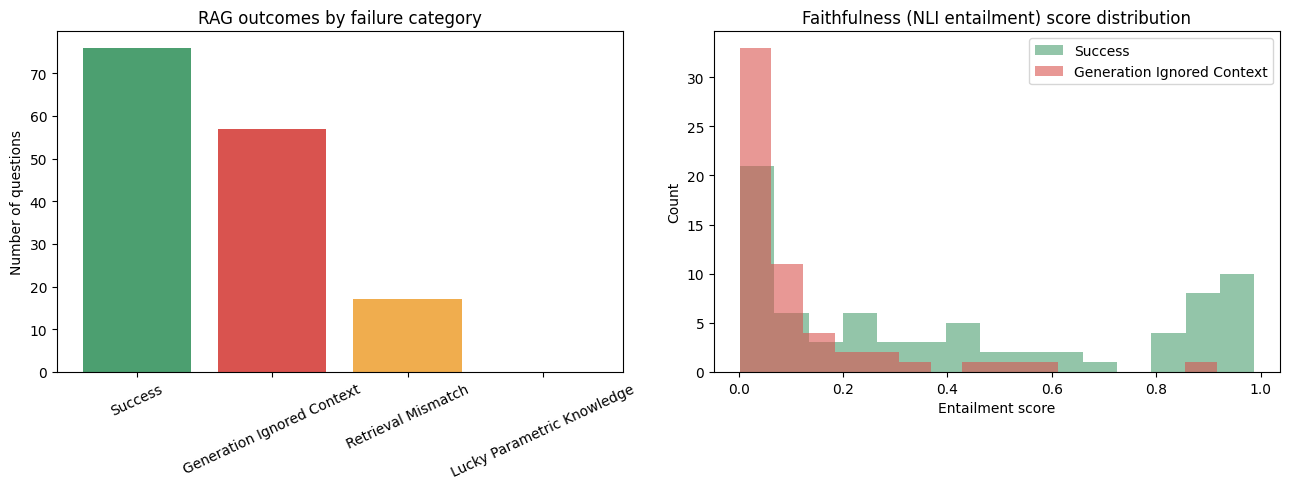

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 8a. Failure category bar chart
order = ["Success", "Generation Ignored Context", "Retrieval Mismatch", "Lucky Parametric Knowledge"]
counts = df["category"].value_counts().reindex(order).fillna(0)
axes[0].bar(counts.index, counts.values, color=["#4C9F70", "#D9534F", "#F0AD4E", "#5BC0DE"])
axes[0].set_title("RAG outcomes by failure category")
axes[0].set_ylabel("Number of questions")
axes[0].tick_params(axis='x', rotation=25)

# 8b. Faithfulness distribution: Success vs Generation Ignored Context
success_faith = df[df["category"] == "Success"]["faithfulness"]
fail_faith = df[df["category"] == "Generation Ignored Context"]["faithfulness"]
axes[1].hist(success_faith, bins=15, alpha=0.6, label="Success", color="#4C9F70")
axes[1].hist(fail_faith, bins=15, alpha=0.6, label="Generation Ignored Context", color="#D9534F")
axes[1].set_title("Faithfulness (NLI entailment) score distribution")
axes[1].set_xlabel("Entailment score")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.savefig("rag_failure_analysis.png", dpi=150)
plt.show()


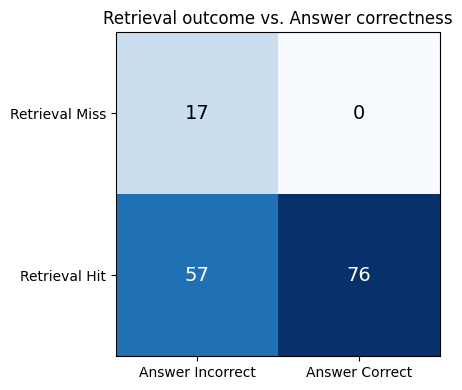

rag_correct,Answer Incorrect,Answer Correct
retrieval_hit,,
Retrieval Miss,17,0
Retrieval Hit,57,76


In [ ]:
# Confusion-style heatmap: retrieval hit/miss x correct/incorrect
pivot = pd.crosstab(df["retrieval_hit"], df["rag_correct"])
pivot.index = pivot.index.map({True: "Retrieval Hit", False: "Retrieval Miss"})
pivot.columns = pivot.columns.map({True: "Answer Correct", False: "Answer Incorrect"})

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(pivot.values, cmap="Blues")
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, pivot.values[i, j], ha="center", va="center",
                 color="white" if pivot.values[i, j] > pivot.values.max()/2 else "black", fontsize=14)
ax.set_title("Retrieval outcome vs. Answer correctness")
plt.tight_layout()
plt.savefig("rag_confusion_matrix.png", dpi=150)
plt.show()

pivot


## 9. Qualitative case studies

The abstract/paper will be much stronger with a few concrete examples. This pulls out cases where **retrieval succeeded but the model still got it wrong** — the most interesting and novel failure mode for the paper's narrative (as opposed to the more "obvious" retrieval-mismatch failures).


In [ ]:
ignored_context_cases = df[df["category"] == "Generation Ignored Context"].sort_values("faithfulness")

N_EXAMPLES = 5
for _, row in ignored_context_cases.head(N_EXAMPLES).iterrows():
    print("=" * 90)
    print("Q:", row["question"])
    print("Gold answer:", row["gold_answer"])
    print("RAG answer:", row["rag_answer"], f"(F1={row['rag_f1']:.2f}, faithfulness={row['faithfulness']:.2f})")
    print("Closed-book answer:", row["closed_book_answer"])
    print("Gold passage (truncated):", row["gold_context"][:300], "...")


Q: What studio does ABC own at 1500 Broadway in NYC?
Gold answer: Times Square Studios
RAG answer: I don't know (F1=0.00, faithfulness=0.00)
Closed-book answer: adobe
Gold passage (truncated): ABC also owns the Times Square Studios at 1500 Broadway on land in Times Square owned by a development fund for the 42nd Street Project; opened in 1999, Good Morning America and Nightline are broadcast from this particular facility. ABC News has premises a little further on West 66th Street, in a si ...
Q: In 1890, who did the university decide to team up with?
Gold answer: several regional colleges and universities
RAG answer: Methodist (F1=0.00, faithfulness=0.00)
Closed-book answer: st john s college
Gold passage (truncated): In the 1890s, the University of Chicago, fearful that its vast resources would injure smaller schools by drawing away good students, affiliated with several regional colleges and universities: Des Moines College, Kalamazoo College, Butler University, and Stetson Universit

## 10. Summary table for the paper/abstract

In [ ]:
summary = {
    "n_questions": len(df),
    "corpus_size": len(corpus_texts),
    "top_k": TOP_K,
    "retrieval_hit_rate": df["retrieval_hit"].mean(),
    "rag_exact_match": df["rag_em"].mean(),
    "rag_f1": df["rag_f1"].mean(),
    "closed_book_exact_match": df["cb_em"].mean(),
    "closed_book_f1": df["cb_f1"].mean(),
    "pct_success": (df["category"] == "Success").mean(),
    "pct_generation_ignored_context": (df["category"] == "Generation Ignored Context").mean(),
    "pct_retrieval_mismatch": (df["category"] == "Retrieval Mismatch").mean(),
    "pct_lucky_parametric": (df["category"] == "Lucky Parametric Knowledge").mean(),
    "mean_faithfulness_success": df.loc[df["category"] == "Success", "faithfulness"].mean(),
    "mean_faithfulness_ignored_context": df.loc[df["category"] == "Generation Ignored Context", "faithfulness"].mean(),
}

summary_df = pd.DataFrame([summary]).T.rename(columns={0: "value"})
summary_df


,value
n_questions,150.000000
corpus_size,950.000000
top_k,5.000000
retrieval_hit_rate,0.886667
rag_exact_match,0.406667
rag_f1,0.483814
closed_book_exact_match,0.040000
closed_book_f1,0.077915
pct_success,0.506667
pct_generation_ignored_context,0.380000


In [ ]:
# Persist everything for the paper: raw results + summary
df.drop(columns=["retrieved_docs"]).to_csv("rag_failure_results.csv", index=False)
summary_df.to_csv("rag_failure_summary.csv")
print("Saved: rag_failure_results.csv, rag_failure_summary.csv, rag_failure_analysis.png, rag_confusion_matrix.png")


Saved: rag_failure_results.csv, rag_failure_summary.csv, rag_failure_analysis.png, rag_confusion_matrix.png


## 11. Notes, limitations & next steps for the full paper

**Limitations of this exploratory run (worth stating explicitly in the abstract):**
- Single retriever (`all-MiniLM-L6-v2`) and single generator (`flan-t5-large`) — results may not generalize to other model families (e.g., decoder-only instruct LLMs like Llama/Mistral/Qwen).
- Faithfulness scoring uses a generic NLI model on a naively-concatenated question+answer string, not a purpose-built claim-verification pipeline — treat it as a proxy signal, not ground truth. For the full paper, consider human annotation of a sample, or a stronger claim-decomposition + verification pipeline (e.g., FActScore-style).
- SQuAD questions are relatively simple (single-passage, extractive) — RAG failure modes may look different on multi-hop (HotpotQA) or open-domain (Natural Questions) datasets.
- `TOP_K` and corpus size directly affect the retrieval hit rate — worth an ablation sweep (k = 1, 3, 5, 10) for the full paper.

**Natural extensions before the Nov 30 full-paper deadline:**
1. Repeat with 2–3 generator models (e.g., an open decoder-only instruct model in addition to Flan-T5) to see if "ignoring context" rates vary by model family/size.
2. Ablate `TOP_K` and distractor corpus size to see how retrieval hit rate trades off against "ignoring context" rate (does giving the model *more* passages increase or decrease hallucination?).
3. Add a human-annotated faithfulness subset (e.g., 50 examples) to validate the NLI-based faithfulness proxy.
4. Try a multi-hop dataset (HotpotQA) where "retrieval mismatch" is more likely to dominate, to see if the failure taxonomy shifts.
5. Test a mitigation (e.g., explicit "cite the passage number you used" prompting, or an abstention-encouraging prompt) and measure whether it shifts mass from "Generation Ignored Context" into "Success" or into safe abstentions.
